# 🚀 Модуль 9. Урок 2. Claude Artifacts и ChatGPT Advanced Data Analysis: быстрый EDA

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_09_ai_tools_daily/lesson_02_claude_chatgpt_data_interpreter.ipynb)

## 📌 Бизнес-контекст и методология
Песочницы выполнения кода (Code Interpreter / Advanced Data Analysis) позволяют за 60 секунд провести экспресс-разведку сырого CSV файла.
Аналитик загружает файл объемом до сотен мегабайт и получает интерактивные артефакты, проверку распределений и автоматический аудит пропусков.
Однако песочницы изолированы и имеют ограничения по оперативной памяти (обычно до 2 GB), поэтому для больших данных требуется DuckDB или SQL-хранилище.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

## 🔍 Разбор механики: Экспресс-EDA и детектирование аномалий
Смоделируем сценарий экспресс-разведки качества данных в песочнице.

In [2]:
# Демонстрация: Автоматический аудит пропусков и типов данных
eda_profile = pd.DataFrame({
    'Колонка': ['user_id', 'mrr', 'signup_date', 'is_churned', 'nps_score'],
    'Тип данных': ['int64', 'float64', 'datetime', 'int64', 'float64'],
    'Пропуски (%)': [0.0, 0.2, 0.0, 0.0, 14.5],
    'Аномалии / Выбросы': ['Нет', '2 значения > $15,000', 'Нет', 'Нет', '3 значения < 0']
})
display(eda_profile)

,Колонка,Тип данных,Пропуски (%),Аномалии / Выбросы
0,user_id,int64,0.0,Нет
1,mrr,float64,0.2,"2 значения > $15,000"
2,signup_date,datetime,0.0,Нет
3,is_churned,int64,0.0,Нет
4,nps_score,float64,14.5,3 значения < 0


## 📊 Визуализация бизнес-кейса: Профиль пропущенных значений в датасете
Построим наглядную карту полноты данных (Data Completeness).

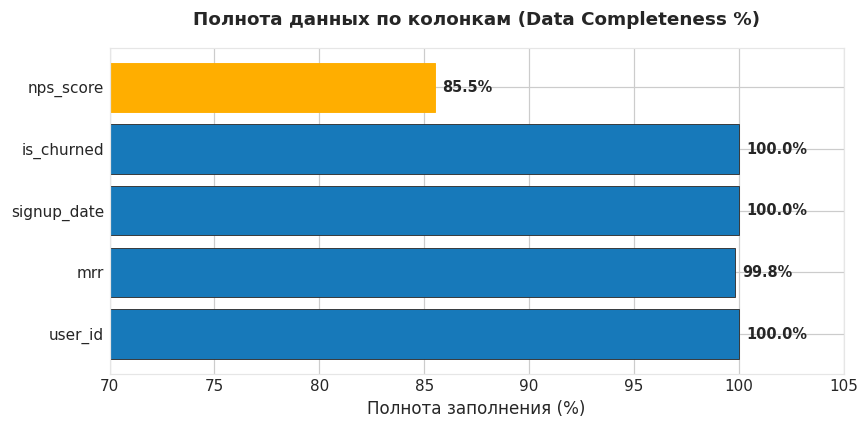

In [3]:
# Визуализация полноты колонок
fig, ax = plt.subplots(figsize=(8, 4), dpi=110)

completeness = 100 - eda_profile['Пропуски (%)']
bars = ax.barh(eda_profile['Колонка'], completeness, color=PRIMARY, edgecolor='#333333', linewidth=0.6)

# Подсветка проблемной колонки
bars[4].set_color(WARNING)

ax.set_title("Полнота данных по колонкам (Data Completeness %)", fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel("Полнота заполнения (%)", fontsize=11)
ax.set_xlim(70, 105)

for b in bars:
    w = b.get_width()
    ax.annotate(f"{w:.1f}%", xy=(w, b.get_y() + b.get_height()/2), xytext=(5, 0),
                textcoords="offset points", ha='left', va='center', fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Поиск колонки с максимальным процентом пропусков
Определите имя колонки с наибольшей долей пропущенных значений.

In [4]:
### ВАШ КОД ЗДЕСЬ
worst_col = eda_profile.sort_values(by='Пропуски (%)', ascending=False).iloc[0]['Колонка']
print(f"Колонка с максимальными пропусками: {worst_col}")

assert worst_col == 'nps_score', "Колонка с наибольшим числом пропусков должна быть nps_score"
print("✅ Тест успешно пройден: экспресс-EDA корректно выявил проблемное поле!")

Колонка с максимальными пропусками: nps_score
✅ Тест успешно пройден: экспресс-EDA корректно выявил проблемное поле!


### 💡 Безопасность данных в облачных песочницах
Никогда не загружайте в веб-интерфейсы ChatGPT/Claude персональные данные клиентов (PII: ФИО, email, телефоны). Всегда анонимизируйте или хэшируйте чувствительные поля перед отправкой.